1. Ridge - 대부분의 속성의 가중치를 0에 가깝게 만든다.(L2)
2. Lasso - 특정 속성들의 가중치를 0으로 만든다.(L1)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import Lasso
from sklearn.model_selection import train_test_split

In [ ]:
# 1. 데이터 준비
arr = np.load('/content/drive/MyDrive/운영/MBC/데이터분석_1기/수업/04_ML/data/boston.npz')
x = arr['x']
y = arr['y']
print(x.shape)
print(y.shape)

(506, 104)
(506,)


In [ ]:
# 2. 학습데이터 분리
x_train,x_test,y_train,y_test = train_test_split(x,y,random_state=42)

# 3. 알고리즘 선택 및 학습(기본값 1)
model = Lasso(alpha=1).fit(x_train,y_train)

print(f'train : {model.score(x_train,y_train)}')
print(f'test : {model.score(x_test,y_test)}')
print(f'사용한 특성 수 : {np.sum(model.coef_!=0)}')


train : 0.26783778369518485
test : 0.2599232118344591
사용한 특성 수 : 3


In [ ]:
# 경사하강법 - 목표가 수렴될때 까지 계속 내려가면서 진행(격차를 줄여나간다.)
# Lasso는 기본 1000번 반복함
# alpha = 1 : 대부분 0에 가있다. -> 0이 아닌 수치를 조절할 변수가 적다 -> 1000번 안에 끝난다.
# alpha = 0.01 : 대부분 0이 아니다. -> 0이 아닌 수치를 조절할 변수가 많다. -> 1000번 안에 안끝난다.
model = Lasso(alpha=0.01, max_iter=100000).fit(x_train,y_train)

print(f'train : {model.score(x_train,y_train)}')
print(f'test : {model.score(x_test,y_test)}')
print(f'사용한 특성 수 : {np.sum(model.coef_!=0)}')

train : 0.8864717420585477
test : 0.8036004116583616
사용한 특성 수 : 34


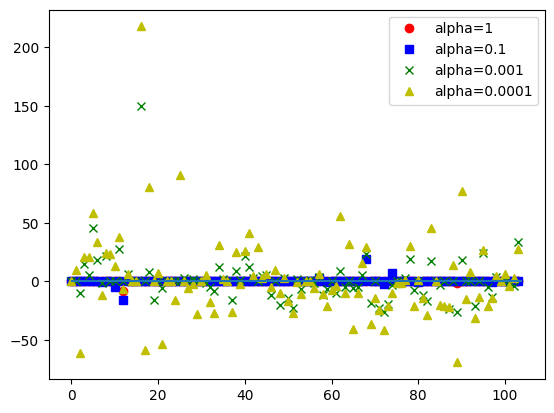

In [ ]:
# Lasso 모델의 alpha 값에 따른 속성 분포 차이
for a,s in zip([1,0.1,0.001,0.0001],['ro','bs','gx','y^']):
  model = Lasso(alpha=a, max_iter=100000).fit(x_train,y_train)
  plt.plot(model.coef_,s,label=f'alpha={a}')

plt.hlines(0,0,len(model.coef_))
plt.legend()
plt.show()

# Ridge 의 alpha = 0.1 과 Lasso 의 alpha=0.1 은 성능이 비슷하다.
# 다만 L1 과 L2 규제의 차이가 있다.

ElasticNet
1. ElasticNet 은 Ridge 와 Lasso 를 조합해서 만들었다.
2. L1_ratio = 0~1 로 L1 과 L2 의 비율을 조정

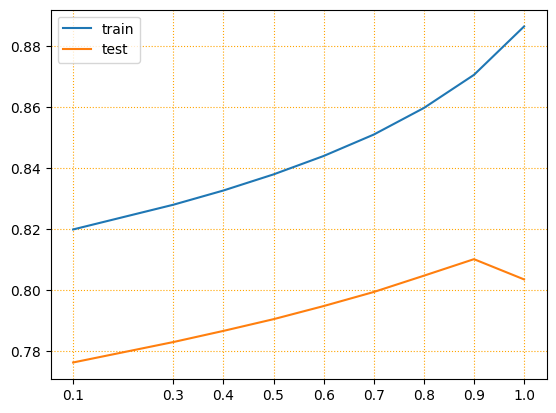

In [ ]:
from sklearn.linear_model import ElasticNet

ratio = [0.1,0.3,0.4,0.5,0.6,0.7,0.8,0.9,1]
train_scores = []
test_scores = []

# alpha = 0.1, l1 = 0.7 # 클수록 대다수가 0
# 0.1 * 0.7 = 0.07
# alpha = 0.1, l2 = 0.3 # 클수록 대다수가 0에 가까움
# (0.1/2) * 0.3 = 0.015

# 알파가 0.1 일 경우
# 0.7 : 0.3 => 0.07 : 0.015
# 0.3 : 0.7 => 0.03 : 0.035
for r in ratio:
  model = ElasticNet(alpha=0.01, l1_ratio=r, max_iter=100000).fit(x_train,y_train)
  train_scores.append(model.score(x_train,y_train))
  test_scores.append(model.score(x_test,y_test))

plt.plot(ratio,train_scores, label='train')
plt.plot(ratio,test_scores, label='test')
plt.xticks(ratio)
plt.grid(True, c='orange', linestyle=':')
plt.legend()
plt.show()